# Прогнозирование значительной высоты морских волн у побережья Калифорнии (NOAA NDBC)

## Постановка задачи и физический контекст
* **Тип ML-задачи:** Регрессия (прогнозирование непрерывной физической величины — значительной высоты волны `WVHT` в метрах) на горизонте 3 и 6 часов вперёд, с прикладным пороговым анализом штормовых тревог для безопасности судоходства.
* **Источник данных:** Официальный архив Национального центра данных буёв США (**National Oceanic and Atmospheric Administration — National Data Buoy Center**) за 2021–2025 гг.
* **Пространственная конфигурация (6 станций):**
  * `46059` (*West California*, глубина 4620 м) — дальний глубоководный буй-дозорный в 357 морских милях в открытом Тихом океане (первым перехватывает зарождающуюся штормовую зыбь).
  * `46022` (*Eel River*, 456 м) → `46014` (*Point Arena*, 265 м) → `46013` (*Bodega Bay*, 120 м) → `46026` (*San Francisco*, 53 м) → `46028` (*Cape San Martin*, 1150 м) — шельфовая цепочка вдоль побережья Калифорнии с севера на юг.

## Этап 1. Сбор, физическая очистка и хронологическое разделение телеметрии буёв NOAA NDBC

**Цель ноутбука:** превратить разрозненные «сырые» 10-минутные текстовые архивы 6 океанских и шельфовых буёв у побережья Калифорнии (2021–2025 гг.) в единую, синхронизированную по времени часовую базу данных и сформировать эталонные выборки `train` / `val` / `test` без утечек из будущего.

**План работы:**

1. Загрузка конфигурации сети из 6 буёв и справочника кодов пропусков NOAA (`src/buoy_config.py`).
2. Инспекция сырого текстового файла (анализ форматов, частоты опроса датчиков и аппаратных заглушек).
3. Очистка и часовая агрегация всех станций с выравниванием на непрерывную временную сетку (`→ data/interim/`).
4. Диагностика структуры пропусков (`NaN`) и доступности датчиков по годам и станциям.
5. Формирование целевых переменных (`+3ч` и `+6ч`), автоматические `assert`-проверки чистоты и разделение на `train` / `val` / `test` (`→ data/processed/`).

In [1]:
import glob
import os
import numpy as np
import pandas as pd

import sys

sys.path.append('..') 

from src.buoy_config import BUOYS_META, NA_BY_COL

## 1. Инспекция исходного формата телеметрии NOAA

Прежде чем писать парсер, откроем первые 25 строк реального архивного файла станции 46028 (Cape San Martin) за 2021 год, чтобы изучить структуру заголовков, частоту записи разных датчиков и формат кодирования пропусков.

In [2]:
sample_file = '../data/raw/station_46028/2021/46028h2021.txt'
with open(sample_file, 'r') as f:
  for _ in range(25):
    print(f.readline().rstrip())

#YY  MM DD hh mm WDIR WSPD GST  WVHT   DPD   APD MWD   PRES  ATMP  WTMP  DEWP  VIS  TIDE
#yr  mo dy hr mn degT m/s  m/s     m   sec   sec degT   hPa  degC  degC  degC   mi    ft
2021 01 01 00 00 324 14.7 17.9 99.00 99.00 99.00 999 9999.0  12.4 999.0  10.0 99.0 99.00
2021 01 01 00 10 325 13.3 16.9 99.00 99.00 99.00 999 9999.0  12.4 999.0  10.3 99.0 99.00
2021 01 01 00 20 328 13.4 16.5 99.00 99.00 99.00 999 9999.0  12.4 999.0  10.3 99.0 99.00
2021 01 01 00 30 327 13.8 17.5 99.00 99.00 99.00 999 9999.0  12.3 999.0  10.2 99.0 99.00
2021 01 01 00 40 326 13.6 17.2  4.28 17.39  8.04 298 9999.0  12.4 999.0  10.2 99.0 99.00
2021 01 01 00 50 328 13.0 17.5 99.00 99.00 99.00 999 9999.0  12.4 999.0  10.4 99.0 99.00
2021 01 01 01 00 331 12.9 16.4 99.00 99.00 99.00 999 9999.0  12.4 999.0  10.1 99.0 99.00
2021 01 01 01 10 330 13.9 18.1 99.00 99.00 99.00 999 9999.0  12.5 999.0   9.9 99.0 99.00
2021 01 01 01 20 329 13.7 18.0 99.00 99.00 99.00 999 9999.0  12.5 999.0   9.8 99.0 99.00
2021 01 01 01 30 332 

### Выводы по сырому файлу и инженерные правила очистки

* **Двойная шапка файла:** первая строка содержит коды измеряемых показателей (`#YY MM DD hh mm...`), а вторая строка — их единицы измерения (`#yr mo dy hr mn degT m/s...`). При чтении через `pd.read_csv` первую строку используем как заголовок (`header=0`), а вторую пропускаем (`skiprows=lambda x: x == 1`).
* **Разная частота опроса датчиков:** метеоприборы (`WDIR`, `WSPD`, `GST`, `PRES`) записывают показания каждые **10 минут**, тогда как волновой акселерометр (`WVHT`, `DPD`, `APD`, `MWD`) срабатывает **1 раз в час** (в остальные 5 отсчётах внутри часа стоят заглушки `99.00` / `999`).
* **Исключение неинформативных колонок (`VIS`, `TIDE`):** датчики горизонтальной видимости и уровня прилива на глубоководных и шельфовых буях этой сети физически не устанавливаются — колонки заполнены `99.0` сплошняком (100% пропусков) и отбрасываются при агрегации.
* **Защита от «ловушки давления `999.0`»:** в стандарте NOAA число `999.0` используется одновременно как код пропуска температуры (`ATMP`, `WTMP`, `DEWP`) и как **реальное штормовое давление** в центре глубокого циклона (`PRES = 999.0 гПа`, тогда как пропуск давления кодируется как `9999.0`). Поэтому замена заглушек на `NaN` выполняется строго поколоночно через словарь `NA_BY_COL`, а не глобальным поиском.

## Словарь исходных переменных

| Признак | Единицы | Физический смысл и описание | Код пропуска NOAA | Роль в модели |
| :--- | :--- | :--- | :---: | :--- |
| `#YY`, `MM`, `DD`, `hh`, `mm` | UTC | Год, месяц, день, час и минута замера (объединяются в `timestamp`) | — | Временной индекс и календарные признаки |
| **`WVHT`** | **м** | **Значительная высота волны** (*Significant Wave Height* — средняя высота 33% самых высоких волн за 20-минутный период записи) | `99.00` | **Целевая переменная ($y_{t+3h}, y_{t+6h}$)** и исторический лаг |
| `WDIR` | град (`degT`) | Направление ветра (откуда дует ветер, истинный азимут $0\text{–}360^\circ$) | `999` | Метеорологический признак (преобразуется в $\sin/\cos$) |
| `WSPD` | м/с | Средняя скорость ветра за 8-минутный интервал | `99.0` | Главный фактор генерации ветровых волн |
| `GST` | м/с | Максимальная скорость порывов ветра за период наблюдения | `99.0` | Индикатор шквальности и турбулентности |
| `DPD` | сек | Доминирующий период волны (период с максимальной спектральной энергией) | `99.00` | Определяет групповую скорость распространения зыби ($c_g = \frac{gT}{4\pi}$) |
| `APD` | сек | Средний период всех волн за период записи | `99.00` | Характеристика крутизны и возраста волнения |
| `MWD` | град (`degT`) | Направление, откуда приходят волны доминирующего периода | `999` | Определяет траекторию переноса волновой энергии к берегу |
| `PRES` | гПа (`hPa`) | Атмосферное давление на уровне моря | `9999.0` | Барический индикатор приближения циклонов ($\Delta P$) |
| `ATMP` | $^\circ\text{C}$ | Температура воздуха над поверхностью океана | `999.0` | Термодинамический признак |
| `WTMP` | $^\circ\text{C}$ | Температура поверхностного слоя воды | `999.0` | В паре с `ATMP` задаёт неустойчивость приводного слоя воздуха |
| `DEWP` | $^\circ\text{C}$ | Температура точки росы (влажность воздуха) | `999.0` | Вспомогательный признак (на части станций отсутствует) |
| `VIS` | морские мили | Горизонтальная видимость | `99.0` | Исключен: датчик не установлен |
| `TIDE` | футы | Уровень прилива | `99.0` | Исключен: датчик не установлен |

## 2. Часовая агрегация и выравнивание на непрерывную сетку (`→ data/interim/`)

Чтобы синхронизировать 10-минутные метеозамеры с ежечасными волновыми данными, переводим все 6 станций на единый часовой шаг (`1h`). Выбор агрегирующих функций определяется физикой каждого датчика:

| Признаки | Агрегат | Физическое обоснование |
| :--- | :---: | :--- |
| `WVHT`, `DPD`, `APD`, `MWD` | `last` | Волновой датчик срабатывает 1 раз в час (5 остальных отсчётов — `NaN`), `last` извлекает единственное реальное измерение за час |
| `WSPD_mean` | `mean` | Средняя скорость ветра за час — базовый показатель потока энергии от ветра к воде |
| `WSPD_std` | `std` | Внутричасовой разброс скорости ветра — индикатор турбулентности и порывистости |
| `GST_max` | `max` | Максимальный пиковый порыв за час — критичен для фиксации шквальных ударов (усреднение «размазало» бы пик) |
| `WDIR` | `last` | Направление ветра на конец часа репрезентативнее простого арифметического среднего (из-за перехода через $0^\circ/360^\circ$) |
| `PRES`, `ATMP`, `WTMP`, `DEWP` | `mean` | Плавные термодинамические величины, где часовое среднее снижает высокочастотный шум датчика |

**Зачем нужно выравнивание на непрерывную часовую сетку (`pd.date_range(freq='1h')`):** при плановом техобслуживании буя в исходных файлах отсутствуют целые недели. Если не заполнить эти интервалы пустыми часовыми строками (`NaN`), будущий сдвиг `shift(-3)` сдвинет данные на 3 строки (то есть через неделю), а не на 3 часа, создав грубую утечку во времени.

In [3]:
def process_buoy(st_id, meta):
    """Читает все файлы буя, очищает коды NOAA, агрегирует в 1 час,
    выравнивает на непрерывную сетку, добавляет метаданные.
    """
    files = sorted(glob.glob(f'../data/raw/station_{st_id}/202*/*.txt'))
    if not files:
        raise FileNotFoundError(f"Нет файлов для буя {st_id} в ../data/raw/station_{st_id}/202*/")
    
    raw = pd.concat(
        [pd.read_csv(f, sep=r'\s+', skiprows=lambda x: x == 1, na_values=NA_BY_COL)
         for f in files],
        ignore_index=True,
    )

    raw['timestamp'] = pd.to_datetime(
        raw[['#YY', 'MM', 'DD', 'hh', 'mm']].rename(
            columns={'#YY': 'year', 'MM': 'month', 'DD': 'day',
                     'hh': 'hour', 'mm': 'minute'})
    )
    raw['timestamp_hour'] = raw['timestamp'].dt.floor('h')

    # часовая агрегация 
    hourly = (
        raw.sort_values('timestamp')
        .groupby('timestamp_hour', as_index=False)
        .agg(WDIR=('WDIR', 'last'),
             WSPD_mean=('WSPD', 'mean'), WSPD_std=('WSPD', 'std'),
             GST_max=('GST', 'max'),
             WVHT=('WVHT', 'last'), DPD=('DPD', 'last'),
             APD=('APD', 'last'), MWD=('MWD', 'last'),
             PRES=('PRES', 'mean'), ATMP=('ATMP', 'mean'),
             WTMP=('WTMP', 'mean'), DEWP=('DEWP', 'mean'))
        .rename(columns={'timestamp_hour': 'timestamp'})
    )

    # выравнивание на непрерывную часовую сетку
    grid = pd.DataFrame({'timestamp': pd.date_range(
        hourly['timestamp'].min(), hourly['timestamp'].max(), freq='1h')})
    hourly = grid.merge(hourly, on='timestamp', how='left')

    # физические метаданные буя
    hourly['station_id'] = st_id
    hourly['lat'] = meta['lat']
    hourly['lon'] = meta['lon']
    hourly['depth_m'] = meta['depth_m']
    first_cols = ['timestamp', 'station_id', 'lat', 'lon', 'depth_m']
    hourly = hourly[first_cols + [c for c in hourly.columns if c not in first_cols]]

    return hourly

In [4]:
# === Цикл-драйвер обработки 6 станций ===
os.makedirs('../data/interim', exist_ok=True)
all_hourly_list = []

for st_id, meta in BUOYS_META.items():
  hourly = process_buoy(st_id, meta)

  # Санитарные проверки физических границ (защита от кодов ошибок NOAA)
  assert hourly['WVHT'].dropna().min() >= 0, f'Буй {st_id}: отрицательная WVHT!'
  assert (
      hourly['PRES'].dropna().min() > 900
  ), f'Буй {st_id}: нереальное давление!'
  assert (
      hourly['WSPD_mean'].dropna().between(0, 60).all()
  ), f'Буй {st_id}: нереальная скорость ветра!'
  assert (
      hourly['DPD'].dropna().between(0, 35).all()
  ), f'Буй {st_id}: нереальный период волны!'
  assert (
      hourly['ATMP'].dropna().between(-10, 45).all()
  ), f'Буй {st_id}: не заменился код 999.0 в ATMP!'

  # Сохраняем почасовой файл станции и добавляем в общий список
  hourly.to_csv(f'../data/interim/buoy_{st_id}_hourly.csv', index=False)
  all_hourly_list.append(hourly)

  valid_wvht = hourly['WVHT'].notna().sum()
  print(
      f"[OK] Буй {st_id} ({meta['name']}): {len(hourly):,} ч | с известной"
      f' WVHT: {valid_wvht:,} ({valid_wvht/len(hourly):.1%})'
  )

all_buoys_hourly = pd.concat(all_hourly_list, ignore_index=True)
all_buoys_hourly.to_csv('../data/interim/all_buoys_hourly.csv', index=False)

print(f'\nИтоговый размер общей часовой таблицы: {all_buoys_hourly.shape}')
print(
    'Чистых часов с известной волной WVHT:'
    f" {all_buoys_hourly['WVHT'].notna().sum():,}"
)

[OK] Буй 46059 (West California): 43,824 ч | с известной WVHT: 30,124 (68.7%)
[OK] Буй 46022 (Eel River): 43,824 ч | с известной WVHT: 25,298 (57.7%)
[OK] Буй 46014 (Point Arena): 43,824 ч | с известной WVHT: 43,473 (99.2%)
[OK] Буй 46013 (Bodega Bay): 43,824 ч | с известной WVHT: 28,676 (65.4%)
[OK] Буй 46026 (San Francisco): 43,824 ч | с известной WVHT: 40,796 (93.1%)
[OK] Буй 46028 (Cape San Martin): 43,824 ч | с известной WVHT: 42,697 (97.4%)

Итоговый размер общей часовой таблицы: (262944, 17)
Чистых часов с известной волной WVHT: 211,064


## 3. Диагностика структуры пропусков (`NaN`) и доступности датчиков

После выравнивания на непрерывную сетку `1h` все аппаратные сбои и периоды техобслуживания буёв материализованы в виде стандартных `NaN`. Построим тепловую карту пропусков по всем датчикам и помесячный таймлайн доступности волнового акселерометра (`WVHT`), чтобы оценить плотность данных и убедиться в отказоустойчивости сети.

In [5]:
display(all_buoys_hourly.head(3))

,timestamp,station_id,lat,lon,depth_m,WDIR,WSPD_mean,WSPD_std,GST_max,WVHT,DPD,APD,MWD,PRES,ATMP,WTMP,DEWP
0,2021-01-01 00:00:00,46059,38.067,-129.895,4620,195.0,5.566667,0.121106,7.6,3.39,12.90,9.92,292.0,1022.966667,14.300000,NaN,14.300000
1,2021-01-01 01:00:00,46059,38.067,-129.895,4620,201.0,5.816667,0.147196,7.6,3.07,12.90,9.38,295.0,1023.066667,14.150000,NaN,14.150000
2,2021-01-01 02:00:00,46059,38.067,-129.895,4620,219.0,7.000000,0.753658,10.0,3.16,14.81,9.54,284.0,1023.033333,14.133333,NaN,14.133333


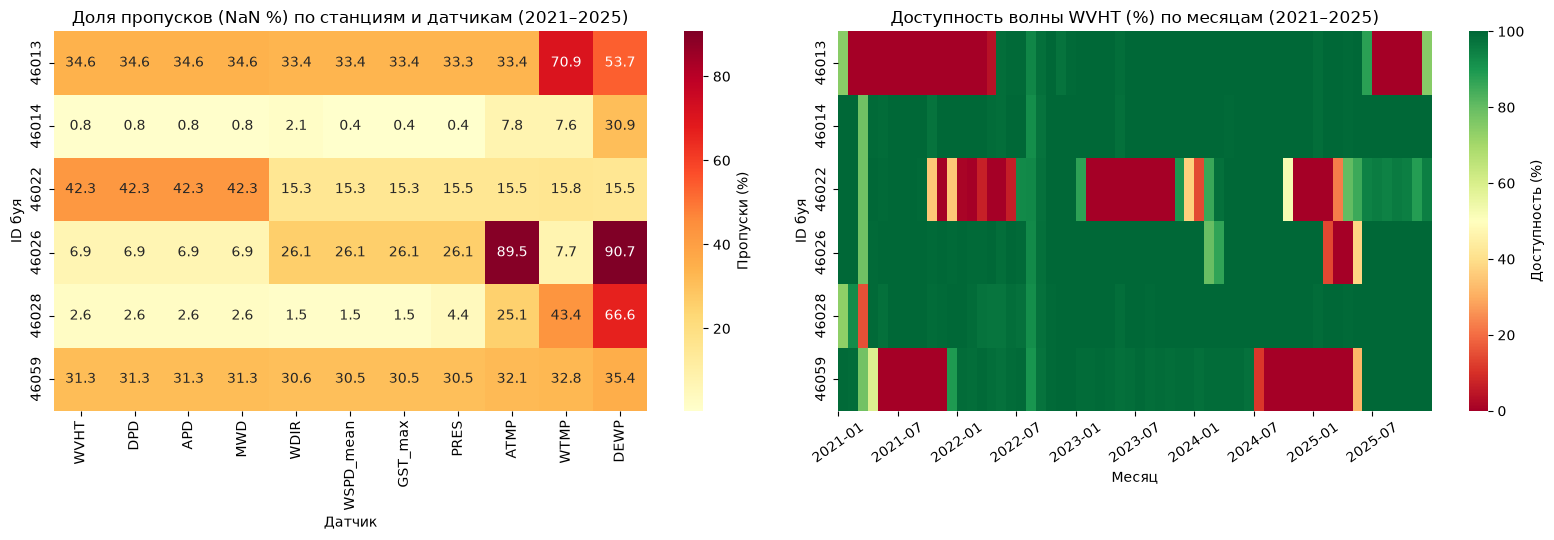

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

feature_cols = [
    'WVHT',
    'DPD',
    'APD',
    'MWD',
    'WDIR',
    'WSPD_mean',
    'GST_max',
    'PRES',
    'ATMP',
    'WTMP',
    'DEWP',
]

# 1. Тепловая карта процента пропусков (NaN %) по каждому бую и датчику
na_matrix = (
    all_buoys_hourly.groupby('station_id')[feature_cols]
    .apply(lambda df: df.isna().mean() * 100)
    .round(1)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

sns.heatmap(
    na_matrix,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    cbar_kws={'label': 'Пропуски (%)'},
    ax=axes[0],
)
axes[0].set_title('Доля пропусков (NaN %) по станциям и датчикам (2021–2025)')
axes[0].set_xlabel('Датчик')
axes[0].set_ylabel('ID буя')

# 2. Таймлайн доступности волнового датчика WVHT по месяцам
df_tmp = all_buoys_hourly[['timestamp', 'station_id', 'WVHT']].copy()
df_tmp['year_month'] = df_tmp['timestamp'].dt.to_period('M').astype(str)
monthly_avail = df_tmp.pivot_table(
    index='station_id',
    columns='year_month',
    values='WVHT',
    aggfunc=lambda s: s.notna().mean() * 100,
)

sns.heatmap(
    monthly_avail,
    cmap='RdYlGn',
    vmin=0,
    vmax=100,
    cbar_kws={'label': 'Доступность (%)'},
    ax=axes[1],
)
axes[1].set_title('Доступность волны WVHT (%) по месяцам (2021–2025)')
axes[1].set_xlabel('Месяц')
axes[1].set_ylabel('ID буя')
axes[1].set_xticks(range(0, len(monthly_avail.columns), 6))
axes[1].set_xticklabels(monthly_avail.columns[::6], rotation=35)

plt.tight_layout()
plt.savefig('../reports/figures/01_missing_data_diagnostics.png', dpi=150)
plt.show()

### Выводы по структуре пропусков и стратегия работы с ними

* **Отказоустойчивость пространственной сети:** опорные станции `46014` (*Point Arena*, 99.2% доступности), `46028` (*Cape San Martin*, 97.4%) и целевой буй `46026` (*San Francisco*, 93.1%) обеспечивают практически непрерывный ряд наблюдений. В периоды локальных сбоев волнового датчика на отдельных буях (например, на `46022` в 2022–2023 гг. или планового ТО `46059` во второй половине 2024 г.) сеть не теряет наблюдаемость за счёт соседних станций.
* **Второстепенные термодатчики:** на прибрежном буе `46026` датчик температуры воздуха `ATMP` практически отсутствует (89.5% пропусков), а датчик точки росы `DEWP` не установлен на части станций (до 90% пропусков). На Этапе 3 мы учтём это, чтобы не строить хрупкие признаки (вроде разности `WTMP - ATMP`), которые обнулят строки на целевой станции.
* **Отказ от синтетической интерполяции:** искусственное заполнение многодневных простоев средними значениями исказило бы физику волнения. Поэтому мы сохраняем честные `NaN`: на Этапе 4 модели `LightGBM` и `CatBoost` обработают их нативно, а для линейного бейзлайна `Ridge` применим `SimpleImputer` строго внутри кросс-валидации.

## 4. Формирование целевых переменных (`+3ч`, `+6ч`) и хронологический сплит

На финальном шаге формируем целевые переменные `target_wvht_3h` и `target_wvht_6h` сдвигом `shift(-3)` и `shift(-6)` строго внутри каждой станции (`groupby('station_id')`). Строки, где отсутствует измерение самой целевой волны (`WVHT` сейчас или через +3/+6 часов), удаляются, так как обучение и расчёт ошибки без известного таргета невозможны.

Чтобы полностью исключить утечку данных из будущего (*Data Leakage*), разделяем датасет строго по календарным годам без перемешивания:

* **`train.csv` (`2021 - 2023` гг.)** - обучение моделей, разведочный анализ (EDA) и подбор признаков;
* **`val.csv` (`2024 г.`)** — валидация и подбор гиперпараметров;
* **`test.csv` (`2025 г.`)** — отложенная финальная проверка качества и диагностика дрейфа данных.

In [7]:
# Формируем целевые переменные (+3ч и +6ч вперёд) строго внутри каждого буя
df_model = all_buoys_hourly.sort_values(['station_id', 'timestamp']).copy()
df_model['target_wvht_3h'] = df_model.groupby('station_id')['WVHT'].shift(-3)
df_model['target_wvht_6h'] = df_model.groupby('station_id')['WVHT'].shift(-6)

df_model = df_model.dropna(
    subset=['WVHT', 'target_wvht_3h', 'target_wvht_6h']
).reset_index(drop=True)

train_df = df_model[df_model['timestamp'].dt.year  < 2024].reset_index(drop=True)
val_df   = df_model[df_model['timestamp'].dt.year == 2024].reset_index(drop=True)
test_df  = df_model[df_model['timestamp'].dt.year == 2025].reset_index(drop=True)

os.makedirs('../data/processed', exist_ok=True)
train_df.to_csv('../data/processed/train.csv', index=False)
val_df.to_csv('../data/processed/val.csv', index=False)
test_df.to_csv('../data/processed/test.csv', index=False)

print(f'train.csv (2021–2023): {train_df.shape} ({len(train_df)/len(df_model):.1%})')
print(f'val.csv   (2024):      {val_df.shape}   ({len(val_df)/len(df_model):.1%})')
print(f'test.csv  (2025):      {test_df.shape}  ({len(test_df)/len(df_model):.1%})')

train.csv (2021–2023): (123615, 19) (59.4%)
val.csv   (2024):      (45258, 19)   (21.8%)
test.csv  (2025):      (39157, 19)  (18.8%)


In [8]:
# Наличие дубликатов в итоговом датасете
assert df_model.duplicated(subset=['timestamp', 'station_id']).sum() == 0

# Границы сплитов не пересекаются
assert train_df['timestamp'].max() < val_df['timestamp'].min(), "train/val пересекаются!"
assert val_df['timestamp'].max()   < test_df['timestamp'].min(), "val/test пересекаются!"

# В таргетах нет NaN 
assert train_df[['target_wvht_3h', 'target_wvht_6h']].isna().sum().sum() == 0
assert val_df[['target_wvht_3h', 'target_wvht_6h']].isna().sum().sum() == 0
assert test_df[['target_wvht_3h', 'target_wvht_6h']].isna().sum().sum() == 0

print(" Все asserts против утечек пройдены")
print(f"  train: {train_df['timestamp'].min()} → {train_df['timestamp'].max()}")
print(f"  val:   {val_df['timestamp'].min()} → {val_df['timestamp'].max()}")
print(f"  test:  {test_df['timestamp'].min()} → {test_df['timestamp'].max()}")

 Все asserts против утечек пройдены
  train: 2021-01-01 00:00:00 → 2023-12-31 23:00:00
  val:   2024-01-01 00:00:00 → 2024-12-31 23:00:00
  test:  2025-01-01 00:00:00 → 2025-12-31 17:00:00
